# Retracer 50 ans d'évolution du Sénégal à travers les données

**FORCE-N — Challenge Data Analytics**

**Réalisé par : Mouhameth DIOP**

## Contexte et problématique

Comment les données peuvent-elles nous aider à comprendre les grandes évolutions économiques, démographiques, sanitaires, éducatives et technologiques du Sénégal sur plusieurs décennies ?

Ce projet consiste à exploiter un jeu de données multidimensionnel issu de la Banque mondiale afin de répondre aux 13 questions du challenge FORCE-N.

## Objectifs

L'objectif est d'explorer les données, de calculer des indicateurs pertinents et de construire des visualisations permettant de mettre en évidence les évolutions observées au Sénégal entre 1975 et 2023.

L'analyse couvre quatre grands thèmes :

- La population et la démographie ;
- L'économie ;
- La santé et l'éducation ;
- Les infrastructures et les technologies.

## Sources et périmètre des données

Les données sont fournies dans une base SQLite contenant une table nommée `population`.

Le jeu de données initial comporte 47 observations et 26 variables. Il couvre les années 1975 à 2024, mais certaines années sont absentes. Le périmètre officiel du challenge s'arrêtant en 2023, l'année 2024 est exclue des analyses.

Les valeurs manquantes sont identifiées et prises en compte selon les besoins de chaque question. Aucune valeur manquante n'est remplacée arbitrairement.

## Environnement technique

- **SQLite / SQL** : exploration de la base de données ;
- **Python** : langage utilisé pour les traitements ;
- **Pandas** : manipulation et analyse des données ;
- **Matplotlib** : création des visualisations.

## Démarche analytique

Le travail suit les principales étapes d'une analyse de données :

1. Découverte de la structure et du contenu de la base ;
2. Vérification de la qualité et de la disponibilité des données ;
3. Sélection des observations nécessaires à chaque question ;
4. Calcul des indicateurs statistiques ;
5. Construction et amélioration des visualisations ;
6. Interprétation des résultats et identification de leurs limites.

L'objectif n'est pas seulement de produire des résultats chiffrés, mais aussi de comprendre ce qu'ils représentent et les précautions nécessaires à leur interprétation.

**Notre base de données est au format SQLite.**

SQLite est un système qui permet de stocker des données dans un fichier de base de données. Au lieu de travailler directement avec un fichier CSV, nous pouvons interroger les données avec SQL.

*Pour communiquer avec cette base depuis Python, nous utiliserons la bibliothèque sqlite3*

In [1]:
#importer SQlite et établir la connexion à la base de données
import sqlite3

connexion = sqlite3.connect("../data/raw/senegal.db")

## 1. Découverte de la structure de la base de données

### Objectif

Avant de commencer notre analyse, nous devons comprendre
comment les données sont organisées dans notre base de données.

Une base SQLite peut contenir plusieurs tables. Nous devons
donc identifier les tables disponibles avant de consulter
leur contenu.

### Méthode

Nous utilisons la table système `sqlite_master` de SQLite
pour récupérer les noms des tables présentes dans la base.

### Outil utilisé

- `sqlite3` : bibliothèque Python permettant de communiquer
  avec une base de données SQLite.
- `cursor()` : permet d'exécuter des requêtes SQL.
- `fetchall()` : récupère l'ensemble des résultats.

In [2]:
curseur = connexion.cursor()

curseur.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
""")

tables = curseur.fetchall()

print(tables)

[('population',)]


## 2. Exploration de la structure de la table population

### Objectif

Après avoir identifié les tables présentes dans notre base,
nous allons examiner la structure de la table `population`.

Nous voulons connaître :
- Le nom de chaque colonne ;
- Le type de données associé à chaque colonne ;
- L'organisation générale de la table.

### Méthode

Nous allons utiliser la commande SQL `PRAGMA table_info()`,
qui permet d'obtenir des informations sur les colonnes d'une table SQLite.

### Pourquoi cette étape ?

Connaître les colonnes et leurs types nous permettra de comprendre
quelles variables sont disponibles pour répondre aux 13 questions
du hackathon.

In [3]:
curseur.execute("PRAGMA table_info(population);")

structure = curseur.fetchall()

for colonne in structure:
    print(colonne)

(0, 'Country', 'TEXT', 0, None, 0)
(1, 'Code', 'TEXT', 0, None, 0)
(2, 'Year', 'BIGINT', 0, None, 0)
(3, 'ElectricityAccess', 'FLOAT', 0, None, 0)
(4, 'AgeDepRatioTotal', 'FLOAT', 0, None, 0)
(5, 'AgeDepRatioOld', 'FLOAT', 0, None, 0)
(6, 'AgeDepRatioYoung', 'FLOAT', 0, None, 0)
(7, 'HealthExpGDP', 'FLOAT', 0, None, 0)
(8, 'ExportsGDP', 'FLOAT', 0, None, 0)
(9, 'GDPPerCapita', 'FLOAT', 0, None, 0)
(10, 'ImportsGDP', 'FLOAT', 0, None, 0)
(11, 'InternetUsage', 'FLOAT', 0, None, 0)
(12, 'Inflation', 'FLOAT', 0, None, 0)
(13, 'LifeExpectancy', 'FLOAT', 0, None, 0)
(14, 'MobileSubs', 'FLOAT', 0, None, 0)
(15, 'FemPop', 'FLOAT', 0, None, 0)
(16, 'MalePop', 'FLOAT', 0, None, 0)
(17, 'TotPop', 'FLOAT', 0, None, 0)
(18, 'PrimaryEnroll', 'FLOAT', 0, None, 0)
(19, 'PrimaryEnrollFem', 'FLOAT', 0, None, 0)
(20, 'PrimaryEnrollMale', 'FLOAT', 0, None, 0)
(21, 'SecondaryEnroll', 'FLOAT', 0, None, 0)
(22, 'SecondaryEnrollFem', 'FLOAT', 0, None, 0)
(23, 'SecondaryEnrollMale', 'FLOAT', 0, None, 0)
(24, '

## 3. Exploration des premières observations

### Objectif

Après avoir identifié les colonnes et leurs types,
nous allons examiner les premières observations de la table.

Cette étape nous permettra de visualiser concrètement
la manière dont les données sont enregistrées.

### Méthode

Nous utilisons une requête SQL `SELECT` pour récupérer
les cinq premières lignes de la table `population`.

La clause `LIMIT 5` limite le nombre de résultats retournés.

### Outil utilisé

- `SELECT *` : sélectionne toutes les colonnes.
- `FROM population` : indique la table à consulter.
- `LIMIT 5` : limite le résultat à cinq lignes.

In [4]:
requete = """
    SELECT *
    FROM population
    LIMIT 5;
"""

curseur.execute(requete)

observations = curseur.fetchall()

for observation in observations:
    print(observation)

('Senegal', 'SEN', 1975, None, 89.5324449305621, 5.08332991226424, 84.4491150182978, None, 21.5488285461405, 547.378148664851, 30.8312081306223, None, 31.6534233153685, 43.938, 0.0, 2554579.0, 2616231.0, 5170810.0, 39.3539581298828, 33.5089416503906, 45.0808181762695, None, None, None, None, 1742201.0)
('Senegal', 'SEN', 1976, None, 90.534923444181, 5.12175101224383, 85.4131724319371, None, 21.4757505862421, 540.594007051938, 32.6400616116536, None, 1.08309218710663, 44.809, 0.0, 2625113.0, 2683451.0, 5308564.0, 38.5845184326172, 32.8224296569824, 44.2303886413574, None, None, None, None, 1824660.0)
('Senegal', 'SEN', 1980, None, 96.436107098248, 5.38367731943208, 91.0524297788159, None, 16.1096048755875, 771.533969550579, 33.1912274280417, None, 8.72902766072327, 48.294, 0.0, 2912666.0, 2932972.0, 5845638.0, 42.2887382507324, 33.9688186645508, 50.4572105407715, 10.3493604660034, 6.78437995910645, 13.8447999954224, None, 2090926.0)
('Senegal', 'SEN', 1981, None, 97.6731423192173, 5.451

## 4. Dimensions du jeu de données

### Objectif

Nous voulons connaître la taille de notre jeu de données.

Deux dimensions nous intéressent :
- Le nombre d'observations (lignes).
- Le nombre de variables (colonnes).

### Méthode

Nous utilisons deux fonctions SQL d'agrégation :
- `COUNT(*)` pour compter les lignes.
- `COUNT(*)` appliqué à `PRAGMA table_info` pour compter les colonnes.

Ces informations nous permettront de mieux caractériser
notre jeu de données avant son audit.

In [5]:
# Nombre de lignes
curseur.execute("SELECT COUNT(*) FROM population;")
nombre_lignes = curseur.fetchone()[0]

# Nombre de colonnes
curseur.execute("PRAGMA table_info(population);")
nombre_colonnes = len(curseur.fetchall())

print(f"Nombre de lignes : {nombre_lignes}")
print(f"Nombre de colonnes : {nombre_colonnes}")

Nombre de lignes : 47
Nombre de colonnes : 26


## 5. Vérification de la couverture temporelle

### Objectif

Le défi porte sur l'évolution du Sénégal sur plusieurs décennies.
Nous devons donc vérifier la période effectivement couverte
par notre jeu de données.

### Méthode

Nous allons utiliser les fonctions SQL suivantes :

- `MIN()` : récupère la plus petite année.
- `MAX()` : récupère la plus grande année.
- `COUNT(DISTINCT ...)` : compte les années différentes.

Nous allons ensuite récupérer la liste des années disponibles
pour identifier d'éventuelles interruptions dans la série temporelle.

### Pourquoi cette étape ?

Une période annoncée ne garantit pas que toutes les années
soient présentes dans les données.
Cette vérification nous évitera de supposer une continuité
qui n'existe peut-être pas.

In [6]:
# Récupération des bornes et du nombre d'années distinctes
requete = """
    SELECT
        MIN(Year),
        MAX(Year),
        COUNT(DISTINCT Year)
    FROM population;
"""

curseur.execute(requete)

premiere_annee, derniere_annee, nombre_annees = curseur.fetchone()

print(f"Première année : {premiere_annee}")
print(f"Dernière année : {derniere_annee}")
print(f"Nombre d'années distinctes : {nombre_annees}")

Première année : 1975
Dernière année : 2024
Nombre d'années distinctes : 47


In [7]:
# Récupération de toutes les années disponibles
requete = """
    SELECT Year
    FROM population
    ORDER BY Year;
"""

curseur.execute(requete)

annees = [ligne[0] for ligne in curseur.fetchall()]

print(annees)

[1975, 1976, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


## 1. Charger les données dans Pandas

Nous avons identifié la structure de la base SQLite et examiné ses premières observations. Nous allons maintenant charger la table population dans un DataFrame Pandas afin de faciliter les opérations d'analyse et de contrôle de la qualité des données.

Nous conservons ici toutes les années présentes dans la base, y compris 2024. La période d'analyse de chaque question sera définie selon les consignes du hackathon.

In [8]:
import pandas as pd

donnees = pd.read_sql_query(
    "SELECT * FROM population ORDER BY Year;",
    connexion
)

## 2. Mesurer les valeurs manquantes

Une valeur manquante correspond à une information qui n'est pas renseignée dans une colonne.

Nous allons calculer, pour chaque variable :
- le nombre de valeurs manquantes ;
- leur pourcentage par rapport aux 47 observations.
Cela nous permettra d'identifier les variables suffisamment renseignées et celles qui nécessiteront une attention particulière.

In [9]:
audit_manquants = pd.DataFrame({
    "Nombre_manquant": donnees.isna().sum(),
    "Pourcentage_manquant": donnees.isna().mean() * 100
})

audit_manquants = audit_manquants[
    audit_manquants["Nombre_manquant"] > 0
].sort_values(
    by="Pourcentage_manquant",
    ascending=False
)

audit_manquants.round(2)

,Nombre_manquant,Pourcentage_manquant
HealthExpGDP,24,51.06
InternetUsage,17,36.17
ElectricityAccess,16,34.04
SecondaryEnrollMale,15,31.91
SecondaryEnrollFem,15,31.91
SecondaryEnroll,13,27.66
UnemploymentRate,13,27.66
MobileSubs,2,4.26
GDPPerCapita,1,2.13
AgeDepRatioYoung,1,2.13


Après avoir mesuré les valeurs manquantes, nous allons identifier les années concernées pour les variables nécessaires à notre analyse.

Cette étape permettra de déterminer sur quelles observations chaque indicateur peut être exploité, sans supprimer ni remplacer arbitrairement des données.

In [10]:
variables_cibles = [
    "GDPPerCapita",
    "LifeExpectancy",
    "UnemploymentRate",
    "TotPop",
    "MalePop",
    "FemPop",
    "PrimaryEnroll",
    "SecondaryEnroll",
    "PrimaryEnrollMale",
    "PrimaryEnrollFem",
    "InternetUsage",
    "UrbanPop"
]

annees_manquantes = []

for variable in variables_cibles:
    annees = donnees.loc[
        donnees[variable].isna(),
        "Year"
    ].tolist()

    if annees:
        annees_manquantes.append({
            "Variable": variable,
            "Annees_manquantes": annees
        })

pd.DataFrame(annees_manquantes)

,Variable,Annees_manquantes
0,GDPPerCapita,[2024]
1,LifeExpectancy,[2024]
2,UnemploymentRate,"[1975, 1976, 1980, 1981, 1982, 1983, 1984, 198..."
3,TotPop,[2024]
4,MalePop,[2024]
5,FemPop,[2024]
6,PrimaryEnroll,[2024]
7,SecondaryEnroll,"[1975, 1976, 1991, 1993, 1994, 1995, 2003, 200..."
8,PrimaryEnrollMale,[2024]
9,PrimaryEnrollFem,[2024]


Certaines listes d'années sont abrégées par l'affichage de Pandas. Nous allons afficher les résultats complets afin de connaître précisément les périodes de disponibilité des indicateurs.

In [11]:
# Parcourir les résultats déjà calculés pour afficher toutes les années.
for resultat in annees_manquantes:
    print(
        f"{resultat['Variable']} : "
        f"{resultat['Annees_manquantes']}"
    )

GDPPerCapita : [2024]
LifeExpectancy : [2024]
UnemploymentRate : [1975, 1976, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990]
TotPop : [2024]
MalePop : [2024]
FemPop : [2024]
PrimaryEnroll : [2024]
SecondaryEnroll : [1975, 1976, 1991, 1993, 1994, 1995, 2003, 2007, 2009, 2016, 2017, 2018, 2024]
PrimaryEnrollMale : [2024]
PrimaryEnrollFem : [2024]
InternetUsage : [1975, 1976, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1991, 1992, 1993, 1994, 2024]
UrbanPop : [2024]


## Définition de la période d'analyse
Le jeu de données contient des observations allant de 1975 à 2024, tandis que le périmètre officiel du hackathon s'arrête en 2023.

Nous allons donc créer un nouveau DataFrame, donnees_analyse, limité à la période 1975–2023.

Nous conservons le DataFrame original donnees afin de préserver les données initiales et de pouvoir revenir à l'ensemble du jeu de données si nécessaire.

In [12]:
# Définir les limites temporelles du hackathon.
annee_debut = 1975
annee_fin = 2023

# Conserver uniquement les observations comprises dans cette période.
donnees_analyse = donnees.loc[
    donnees["Year"].between(annee_debut, annee_fin)
].copy()

# Afficher le nombre d'observations retenues.
print(f"Nombre d'observations : {len(donnees_analyse)}")

Nombre d'observations : 46


## Question 1 — PIB moyen par habitant entre 2000 et 2020
Nous cherchons à déterminer la valeur moyenne du PIB par habitant du Sénégal sur la période 2000–2020.

Pour cela, nous sélectionnons les années comprises entre *2000 et 2020*, ainsi que les valeurs correspondantes de **GDPPerCapita**.

Cette sélection permet de travailler uniquement avec les informations nécessaires à notre question, sans modifier le jeu de données principal.

In [13]:
# Sélectionner les années et le PIB par habitant sur la période étudiée.
donnees_q1 = donnees_analyse.loc[
    donnees_analyse["Year"].between(2000, 2020),
    ["Year", "GDPPerCapita"]
].copy()

# Afficher les observations sélectionnées.
donnees_q1

,Year,GDPPerCapita
22,2000,603.233162
23,2001,637.213531
24,2002,669.430447
25,2003,817.888034
26,2004,918.102080
27,2005,979.846102
28,2006,1017.201967
29,2007,1188.938778
30,2008,1398.792180
31,2009,1308.694043


**Les 21 observations de PIB par habitant sont disponibles pour la période 2000–2020. Nous pouvons donc calculer leur moyenne arithmétique.**

In [14]:
# Calculer la moyenne du PIB par habitant sur la période.
moyenne_pib_habitant = donnees_q1["GDPPerCapita"].mean()

# Afficher le résultat avec deux décimales.
print(f"PIB moyen par habitant : {moyenne_pib_habitant:.2f} USD")

PIB moyen par habitant : 1165.79 USD


### Résultat — Question 1

**Entre 2000 et 2020, le PIB moyen par habitant du Sénégal était de 1 165,79 USD. Ce résultat correspond à la moyenne arithmétique des 21 valeurs annuelles disponibles sur cette période.**

## Question 2 — Calcul de l'espérance de vie moyenne par décennie

Pour répondre à cette question, nous allons regrouper les observations par décennie, puis calculer la moyenne de l'espérance de vie pour chaque groupe.

Nous ajoutons également le nombre d'observations utilisées afin de vérifier la couverture de chaque décennie. Cette précaution est importante : notre période d'analyse commence en 1975 et se termine en 2023. Les décennies 1970 et 2020 sont donc partielles dans notre jeu de données.

In [15]:
# Isoler les variables nécessaires à cette analyse.
donnees_q2 = donnees_analyse.loc[
    :, ["Year", "LifeExpectancy"]
].copy()

# Associer chaque année à sa décennie.
donnees_q2["Decennie"] = (donnees_q2["Year"] // 10) * 10

# Calculer la moyenne et le nombre d'observations par décennie.
esperance_vie_par_decennie = (
    donnees_q2
    .groupby("Decennie", as_index=False)
    .agg(
        nombre_observations=("LifeExpectancy", "count"),
        esperance_vie_moyenne=("LifeExpectancy", "mean")
    )
)

# Afficher les résultats avec deux décimales.
esperance_vie_par_decennie.round(2)

,Decennie,nombre_observations,esperance_vie_moyenne
0,1970,2,44.37
1,1980,10,52.24
2,1990,10,57.18
3,2000,10,60.69
4,2010,10,66.12
5,2020,4,67.71


### Résultat — Question 2

**L'analyse révèle une progression de l'espérance de vie moyenne au Sénégal au fil des décennies. Elle passe de 44,37 ans pour les observations disponibles dans les années 1970 à 66,12 ans dans les années 2010, puis atteint 67,71 ans sur la période 2020–2023.**

**Les moyennes des années 1970 et 2020 doivent toutefois être interprétées avec prudence : elles reposent respectivement sur deux et quatre observations, contrairement aux décennies intermédiaires qui en comptent dix.**

**Ces résultats décrivent une évolution historique, sans permettre à eux seuls d'en expliquer les causes.**

## Question 3 — Visualisation de l'espérance de vie moyenne par décennie

À partir des moyennes calculées précédemment, nous allons représenter graphiquement l'évolution de l'espérance de vie moyenne au Sénégal.

Ce graphique permettra de comparer les différentes décennies et d'observer la tendance générale. Les périodes 1970 et 2020 étant partielles, leur nombre d'observations devra être pris en compte dans l'interprétation.

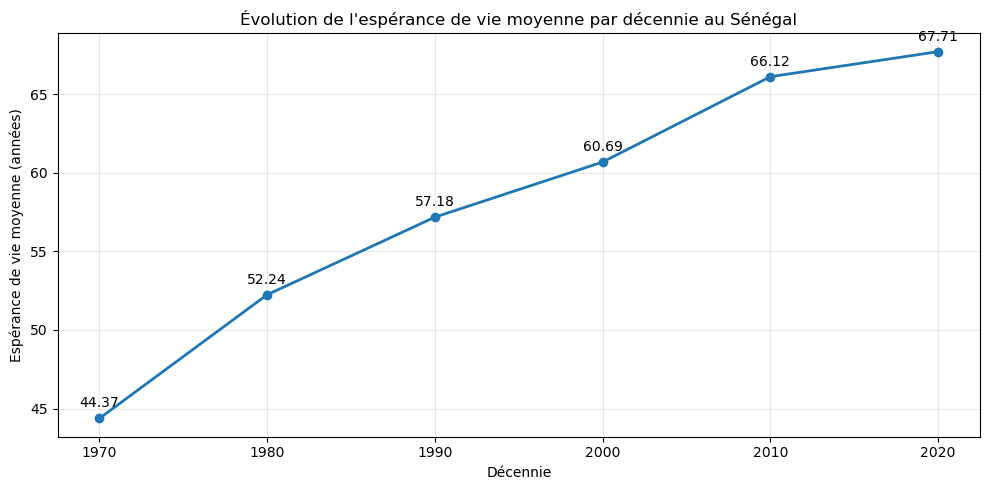

In [16]:
import matplotlib.pyplot as plt

# Créer la figure et définir sa taille.
plt.figure(figsize=(10, 5))

# Tracer l'évolution de l'espérance de vie moyenne.
plt.plot(
    esperance_vie_par_decennie["Decennie"],
    esperance_vie_par_decennie["esperance_vie_moyenne"],
    marker="o",
    linewidth=2
)

# Ajouter le titre et les noms des axes.
plt.title("Évolution de l'espérance de vie moyenne par décennie au Sénégal")
plt.xlabel("Décennie")
plt.ylabel("Espérance de vie moyenne (années)")

# Afficher les valeurs sur chaque point.
for _, ligne in esperance_vie_par_decennie.iterrows():
    plt.annotate(
        f"{ligne['esperance_vie_moyenne']:.2f}",
        (ligne["Decennie"], ligne["esperance_vie_moyenne"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.xticks(esperance_vie_par_decennie["Decennie"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Résultat — Question 3

Le graphique met en évidence une progression régulière de l'espérance de vie moyenne au Sénégal entre les décennies étudiées.

Elle passe de 44,37 ans pour les observations disponibles dans les années 1970 à 67,71 ans pour la période 2020–2023.

Cette évolution traduit une amélioration importante de l'espérance de vie sur la période étudiée. Toutefois, le graphique présente des moyennes décennales et ne permet pas, à lui seul, d'identifier les facteurs expliquant cette progression.

Les décennies 1970 et 2020 sont partielles et doivent être interprétées en tenant compte du nombre d'observations disponibles.

## Question 4 & 5 - Identification de l'année ayant enregistré le taux de chômage le plus élevé et la valeur

Nous cherchons à identifier le taux de chômage maximal enregistré au Sénégal sur la période d'analyse (1975–2023), ainsi que l'année correspondante.

Pour cela, nous allons examiner les observations disponibles de la variable `UnemploymentRate`, ignorer les valeurs manquantes et identifier la ligne contenant la valeur maximale.

Il convient de rappeler que les données de chômage ne sont disponibles qu'à partir de 1991 dans notre jeu de données.

In [17]:
# Sélectionner l'année et le taux de chômage.
donnees_chomage = donnees_analyse.loc[
    :, ["Year", "UnemploymentRate"]
].dropna(subset=["UnemploymentRate"]).copy()

# Identifier la ligne correspondant au taux de chômage maximal.
indice_max = donnees_chomage["UnemploymentRate"].idxmax()
observation_max = donnees_chomage.loc[indice_max]

# Extraire l'année et la valeur maximale.
annee_max_chomage = int(observation_max["Year"])
taux_max_chomage = observation_max["UnemploymentRate"]

# Afficher les résultats.
print(f"Année du taux de chômage maximal : {annee_max_chomage}")
print(f"Taux de chômage maximal : {taux_max_chomage:.2f} %")

Année du taux de chômage maximal : 2015
Taux de chômage maximal : 6.76 %


## Question 6 - Calcul de la croissance globale de la population entre 1990 et 2020

Pour mesurer l'évolution de la population sénégalaise entre 1990 et 2020, nous allons récupérer les populations totales enregistrées durant ces deux années.

Nous utiliserons ensuite ces deux valeurs pour calculer le taux de croissance global sur la période.

In [18]:
# Sélectionner les populations totales de 1990 et 2020.
donnees_q6 = donnees_analyse.loc[
    donnees_analyse["Year"].isin([1990, 2020]),
    ["Year", "TotPop"]
].copy()

# Afficher les deux observations.
donnees_q6

,Year,TotPop
12,1990,7720523.0
42,2020,16789219.0


### Calcul du taux de croissance global

Le taux de croissance global mesure l'augmentation de la population entre deux dates, exprimée en pourcentage de la population initiale.

Nous calculons la différence entre la population finale et la population initiale, puis nous rapportons cette différence à la population de départ.

In [19]:
# Récupérer la population de départ et la population finale.
population_1990 = donnees_q6.loc[
    donnees_q6["Year"] == 1990, "TotPop"
].iloc[0]

population_2020 = donnees_q6.loc[
    donnees_q6["Year"] == 2020, "TotPop"
].iloc[0]

# Calculer le taux de croissance global.
taux_croissance = (
    (population_2020 - population_1990)
    / population_1990
) * 100

print(f"Taux de croissance global : {taux_croissance:.2f} %")

Taux de croissance global : 117.46 %


### Résultat — Question 6

Entre 1990 et 2020, la population totale du Sénégal est passée de 7 720 523 à 16 789 219 habitants.

Cela correspond à un taux de croissance global de **117,46 %**, soit une augmentation d'environ 9,07 millions d'habitants sur cette période de 30 ans.

La population sénégalaise a donc plus que doublé entre 1990 et 2020.

## Question 7 — Évolution du PIB par habitant et de l'espérance de vie

Nous souhaitons observer l'évolution du PIB par habitant et de l'espérance de vie au Sénégal entre 1975 et 2023.

Ces deux indicateurs possèdent des unités et des échelles différentes. Nous utiliserons donc deux axes verticaux pour faciliter leur lecture sur un même graphique.

La première étape consiste à sélectionner les trois variables nécessaires à cette représentation.

In [20]:
donnees_q7 = donnees_analyse.loc[
    :, ["Year", "GDPPerCapita", "LifeExpectancy"]
].copy()

donnees_q7.head()

,Year,GDPPerCapita,LifeExpectancy
0,1975,547.378149,43.938
1,1976,540.594007,44.809
2,1980,771.533970,48.294
3,1981,682.972070,49.083
4,1982,651.937123,49.863


### Construction du graphique à deux axes

Le PIB par habitant et l'espérance de vie sont exprimés dans des unités différentes. Les représenter sur un seul axe vertical rendrait leur lecture difficile.

Nous allons donc utiliser deux axes verticaux :
- un axe à gauche pour le PIB par habitant (USD) ;
- un axe à droite pour l'espérance de vie (années).

Ce graphique permettra de comparer les évolutions temporelles des deux indicateurs, sans supposer l'existence d'un lien de causalité entre eux.

### Pour représenter fidèlement l'évolution des indicateurs, nous devons tenir compte des années absentes de la base de données.

Les années 1977, 1978 et 1979 ne disposent d'aucune observation. Nous allons donc compléter l'index temporel avec toutes les années de 1975 à 2023. Les valeurs manquantes resteront représentées par `NaN`, ce qui permettra à Matplotlib d'interrompre les courbes au lieu de relier artificiellement les observations de 1976 et 1980.

In [21]:
# Créer une série temporelle continue de 1975 à 2023.
donnees_q7_complete = (
    donnees_q7
    .set_index("Year")
    .reindex(range(1975, 2024))
    .rename_axis("Year")
    .reset_index()
)

donnees_q7_complete.head(8)

,Year,GDPPerCapita,LifeExpectancy
0,1975,547.378149,43.938
1,1976,540.594007,44.809
2,1977,NaN,NaN
3,1978,NaN,NaN
4,1979,NaN,NaN
5,1980,771.533970,48.294
6,1981,682.972070,49.083
7,1982,651.937123,49.863


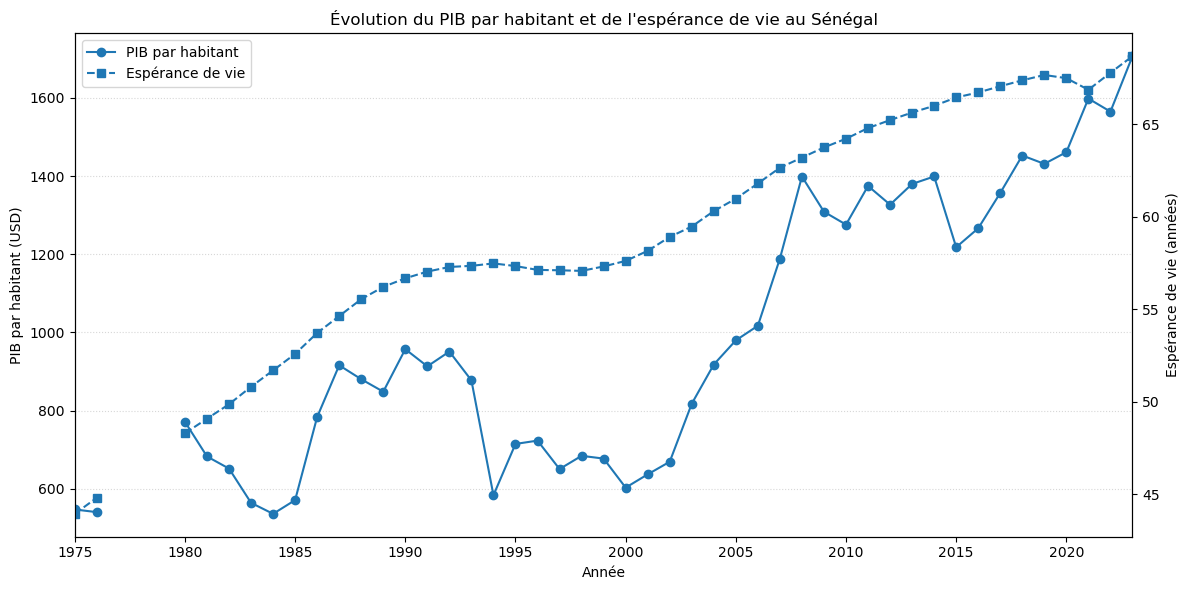

In [22]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Premier axe : PIB par habitant
ax1.plot(
    donnees_q7_complete["Year"],
    donnees_q7_complete["GDPPerCapita"],
    marker="o",
    label="PIB par habitant"
)

ax1.set_xlabel("Année")
ax1.set_ylabel("PIB par habitant (USD)")

# Deuxième axe : espérance de vie
ax2 = ax1.twinx()

ax2.plot(
    donnees_q7_complete["Year"],
    donnees_q7_complete["LifeExpectancy"],
    marker="s",
    linestyle="--",
    label="Espérance de vie"
)

ax2.set_ylabel("Espérance de vie (années)")

# Afficher une graduation tous les cinq ans
ax1.set_xticks(range(1975, 2024, 5))
ax1.set_xlim(1975, 2023)

# Réunir les deux légendes
lignes1, etiquettes1 = ax1.get_legend_handles_labels()
lignes2, etiquettes2 = ax2.get_legend_handles_labels()

ax1.legend(
    lignes1 + lignes2,
    etiquettes1 + etiquettes2,
    loc="upper left"
)

plt.title(
    "Évolution du PIB par habitant et de l'espérance de vie au Sénégal"
)

ax1.grid(axis="y", linestyle=":", alpha=0.5)

fig.tight_layout()
plt.show()

### Le graphique met en évidence deux évolutions distinctes au Sénégal entre 1975 et 2023.

L'espérance de vie présente une tendance globalement croissante sur la période, malgré quelques ralentissements et fluctuations.

Le PIB par habitant connaît une évolution plus irrégulière, avec plusieurs périodes de progression et de recul. Il affiche néanmoins une tendance globale à la hausse sur la période étudiée.

Cette représentation permet de comparer les trajectoires temporelles des deux indicateurs. Cependant, elle ne permet pas, à elle seule, d'établir une corrélation statistique ou un lien de causalité entre le PIB par habitant et l'espérance de vie.

Enfin, les interruptions des courbes entre 1976 et 1980 signalent l'absence d'observations pour les années 1977, 1978 et 1979.

## Question 8 — Évolution des taux de scolarisation

Nous allons étudier l'évolution des taux de scolarisation dans le primaire et le secondaire au Sénégal entre 1975 et 2023.

Les deux indicateurs sont des taux de scolarisation bruts, exprimés en pourcentage. Nous allons les représenter sur un même axe vertical afin de comparer leurs évolutions.

Certaines années ne disposent pas de données pour le secondaire. Ces absences seront conservées et visibles dans la représentation graphique.

Un taux brut de scolarisation rapporte le nombre total d'élèves inscrits dans un niveau d'enseignement à la population ayant l'âge officiel de fréquenter ce niveau. Il peut donc dépasser 100 %, notamment lorsque des élèves plus jeunes ou plus âgés que l'âge officiel sont inscrits. Il ne représente pas directement la proportion des enfants d'âge officiel effectivement scolarisés.


In [23]:
donnees_q8 = donnees_analyse.loc[
    :, ["Year", "PrimaryEnroll", "SecondaryEnroll"]
].copy()

# Compléter l'index temporel sans inventer de valeurs.
donnees_q8_complete = (
    donnees_q8
    .set_index("Year")
    .reindex(range(1975, 2024))
    .rename_axis("Year")
    .reset_index()
)

donnees_q8_complete.head()

,Year,PrimaryEnroll,SecondaryEnroll
0,1975,39.353958,NaN
1,1976,38.584518,NaN
2,1977,NaN,NaN
3,1978,NaN,NaN
4,1979,NaN,NaN


**Avant de construire le graphique, nous examinons le nombre d'observations disponibles pour chaque indicateur.**

Cette vérification permet de mesurer la couverture des données et d'identifier les limites de comparaison entre les deux séries.

In [24]:
nombre_observations_q8 = donnees_q8_complete[
    ["PrimaryEnroll", "SecondaryEnroll"]
].count()

print(nombre_observations_q8)

PrimaryEnroll      46
SecondaryEnroll    34
dtype: int64


### Visualisation de l'évolution de la scolarisation

Nous représentons les taux bruts de scolarisation dans le primaire et le secondaire sur un même graphique.

Les deux indicateurs étant exprimés en pourcentage, ils peuvent partager le même axe vertical.

Les valeurs manquantes sont conservées afin de rendre visibles les périodes pour lesquelles les données ne sont pas disponibles. L'axe vertical commence à zéro pour faciliter la comparaison des niveaux des deux indicateurs.

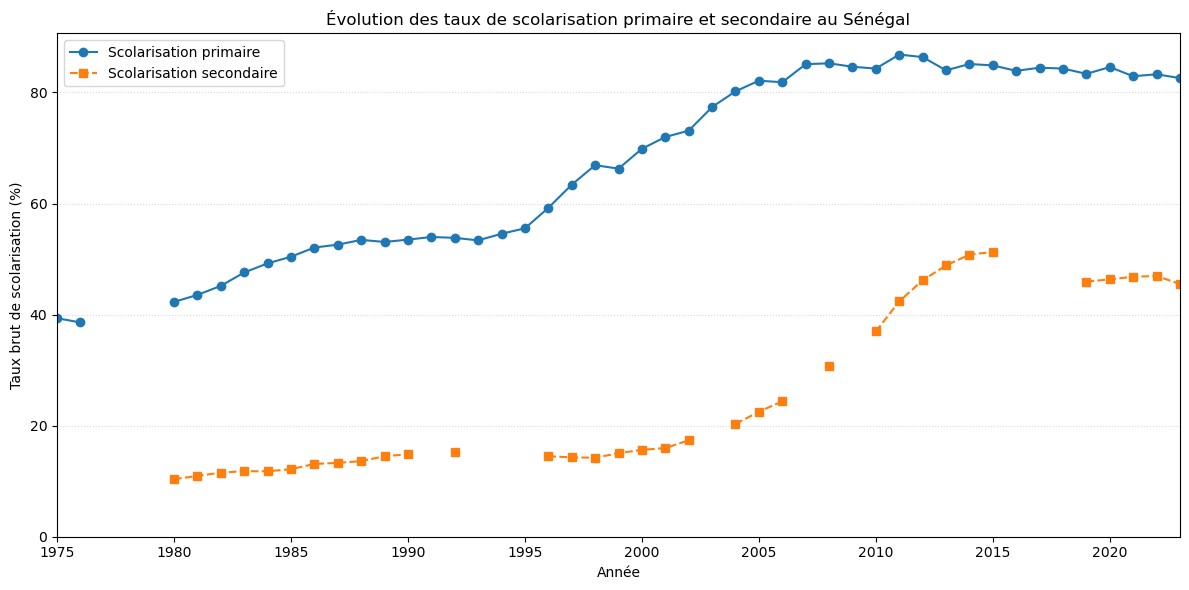

In [25]:
fig, ax = plt.subplots(figsize=(12, 6))

# Taux de scolarisation dans le primaire
ax.plot(
    donnees_q8_complete["Year"],
    donnees_q8_complete["PrimaryEnroll"],
    marker="o",
    label="Scolarisation primaire"
)

# Taux de scolarisation dans le secondaire
ax.plot(
    donnees_q8_complete["Year"],
    donnees_q8_complete["SecondaryEnroll"],
    marker="s",
    linestyle="--",
    label="Scolarisation secondaire"
)

ax.set_xlabel("Année")
ax.set_ylabel("Taux brut de scolarisation (%)")

# L'axe vertical commence à zéro.
ax.set_ylim(bottom=0)

# Afficher une graduation tous les cinq ans.
ax.set_xticks(range(1975, 2024, 5))
ax.set_xlim(1975, 2023)

ax.set_title(
    "Évolution des taux de scolarisation primaire et secondaire au Sénégal"
)

ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.5)

fig.tight_layout()
plt.show()

**Le graphique met en évidence une progression globale des taux bruts de scolarisation dans l'enseignement primaire et secondaire au Sénégal.**

Dans le primaire, le taux connaît une augmentation importante entre 1975 et les années 2000, avant de se stabiliser à un niveau relativement élevé, autour de 82 à 86 %.

Dans le secondaire, la progression est également visible entre 1980 et 2015. Les observations disponibles entre 2019 et 2023 indiquent ensuite une relative stabilisation autour de 46 à 47 %.

Sur les périodes où les deux indicateurs sont observés, le taux de scolarisation primaire demeure supérieur à celui du secondaire. Cela met en évidence un écart entre les deux niveaux d'enseignement.

L'interprétation doit toutefois tenir compte des données manquantes, particulièrement nombreuses pour le secondaire. Les tendances observées ne permettent pas, à elles seules, d'expliquer les causes de ces évolutions.

## Question 9 — Corrélation entre les taux de scolarisation primaire et secondaire

Nous souhaitons mesurer la relation linéaire entre les taux bruts de scolarisation primaire et secondaire.

Le calcul de corrélation nécessite des observations appariées : chaque taux primaire doit être associé au taux secondaire de la même année.

Nous excluons donc les observations pour lesquelles l'un des deux indicateurs est manquant. Aucune valeur ne sera imputée.

In [26]:
donnees_q9 = donnees_q8_complete.dropna(
    subset=["PrimaryEnroll", "SecondaryEnroll"]
).copy()

print(f"Nombre d'observations appariées : {len(donnees_q9)}")

Nombre d'observations appariées : 34


**Nous calculons le coefficient de corrélation de Pearson entre les taux bruts de scolarisation primaire et secondaire, à partir des 34 observations appariées.**

Ce coefficient permettra d'évaluer le sens et l'intensité de leur relation linéaire dans les observations disponibles.

In [27]:
correlation_q9 = donnees_q9[
    ["PrimaryEnroll", "SecondaryEnroll"]
].corr(method="pearson")

correlation_q9

,PrimaryEnroll,SecondaryEnroll
PrimaryEnroll,1.000000,0.840806
SecondaryEnroll,0.840806,1.000000


### Interprétation du coefficient

Le coefficient de corrélation de Pearson obtenu est de **0,8408**. Il indique une forte association linéaire positive entre les taux bruts de scolarisation primaire et secondaire sur les 34 années pour lesquelles les deux indicateurs sont disponibles.

Les deux indicateurs nationaux ont donc tendance à évoluer dans le même sens au cours d'une même année. Cette corrélation ne signifie toutefois pas que les mêmes élèves fréquentent simultanément les deux niveaux, ni que la hausse du taux primaire entraîne directement celle du taux secondaire.

Il faut distinguer cette comparaison annuelle d'une analyse de parcours scolaire. Par exemple, les élèves qui entrent au primaire une année donnée peuvent rejoindre le secondaire plusieurs années plus tard. Pour étudier cette hypothèse, il faudrait réaliser une analyse décalée dans le temps (avec plusieurs années de décalage) et, pour suivre réellement les élèves d'une cohorte, disposer de données de cohortes ou de suivi individuel.

Enfin, la progression générale des deux indicateurs au fil du temps peut contribuer à expliquer la corrélation observée. Le coefficient calculé ici ne permet donc pas d'établir un lien de causalité.


## Question 10 : calculer et visualiser l’écart entre les taux bruts de scolarisation des garçons et des filles dans le primaire au fil des années.

### Pour étudier les différences entre les sexes dans l'enseignement primaire, nous comparons les taux bruts de scolarisation des garçons et des filles pour chaque année. Nous calculons ensuite leur écart en points de pourcentage, en définissant cet écart comme le taux masculin moins le taux féminin.

In [28]:
donnees_q10 = donnees_analyse.loc[
    :,
    ["Year", "PrimaryEnrollMale", "PrimaryEnrollFem"]
].copy()

donnees_q10["Ecart"] = (
    donnees_q10["PrimaryEnrollMale"]
    - donnees_q10["PrimaryEnrollFem"]
)

donnees_q10.head()

,Year,PrimaryEnrollMale,PrimaryEnrollFem,Ecart
0,1975,45.080818,33.508942,11.571877
1,1976,44.230389,32.822430,11.407959
2,1980,50.457211,33.968819,16.488392
3,1981,52.000118,34.936939,17.063179
4,1982,54.054291,36.141941,17.912350


Les premières observations montrent un écart variable entre les taux des garçons et des filles. Pour éviter de tirer une conclusion générale à partir de quelques années seulement, nous examinons la distribution de l'écart sur l'ensemble des observations disponibles.

La méthode `describe()` fournit notamment le nombre d'observations, la moyenne, l'écart-type, les valeurs minimale et maximale ainsi que les quartiles. Ces statistiques permettent de résumer l'ampleur et la répartition des écarts avant leur représentation graphique.


In [29]:
donnees_q10["Ecart"].describe().round(2)

count    46.00
mean      5.27
std      12.00
min     -14.14
25%      -9.25
50%       9.54
75%      16.34
max      19.49
Name: Ecart, dtype: float64

Ce graphique compare l'évolution des taux bruts de scolarisation des garçons et des filles dans le primaire au Sénégal, ainsi que l'écart entre ces deux taux. Il permet d'observer simultanément les niveaux de scolarisation et l'évolution des différences entre les sexes.

In [30]:
donnees_q10_complete = (
    donnees_q10
    .set_index("Year")
    .reindex(range(1975, 2024))
    .rename_axis("Year")
    .reset_index()
)

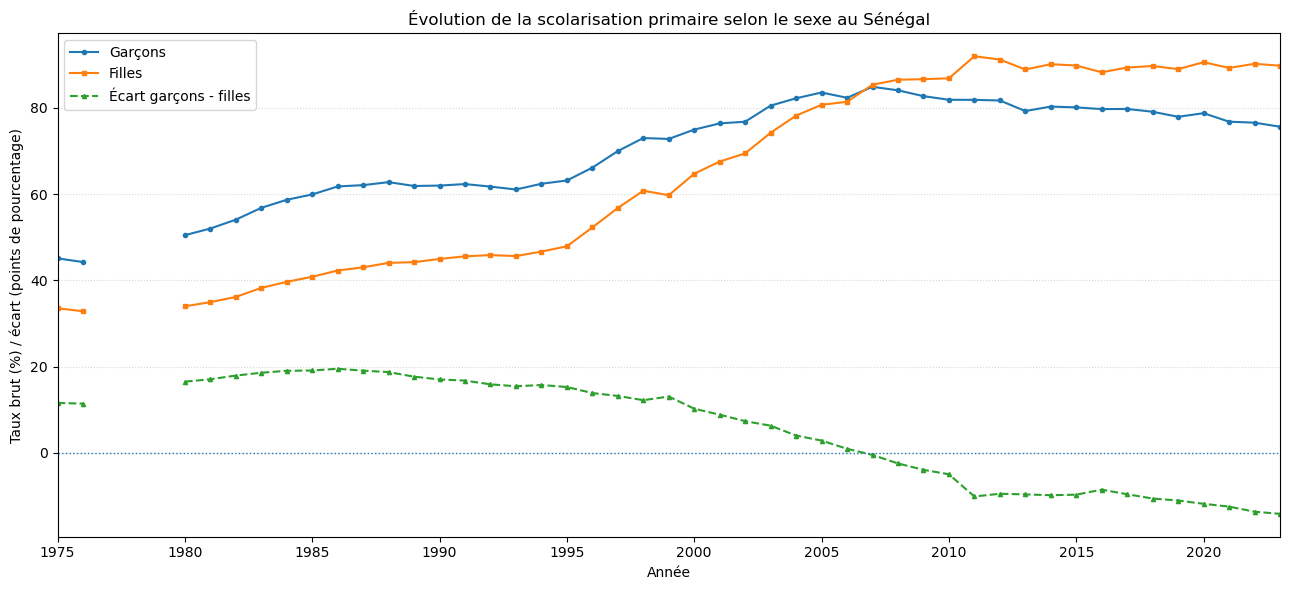

In [31]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    donnees_q10_complete["Year"],
    donnees_q10_complete["PrimaryEnrollMale"],
    marker="o",
    markersize=3,
    label="Garçons"
)

ax.plot(
    donnees_q10_complete["Year"],
    donnees_q10_complete["PrimaryEnrollFem"],
    marker="s",
    markersize=3,
    label="Filles"
)

ax.plot(
    donnees_q10_complete["Year"],
    donnees_q10_complete["Ecart"],
    linestyle="--",
    marker="^",
    markersize=3,
    label="Écart garçons - filles"
)

ax.axhline(0, linestyle=":", linewidth=1)

ax.set_title(
    "Évolution de la scolarisation primaire selon le sexe au Sénégal"
)
ax.set_xlabel("Année")
ax.set_ylabel("Taux brut (%) / écart (points de pourcentage)")

ax.set_xticks(range(1975, 2024, 5))
ax.set_xlim(1975, 2023)

ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.5)

fig.tight_layout()
plt.show()

## Question 11/12 : quelle année présente le plus grand écart entre la population masculine et la population féminine ? Quelle est sa valeur

### Nous cherchons à identifier l'année durant laquelle la différence entre la population masculine et la population féminine du Sénégal est la plus importante. Pour cela, nous calculons la différence absolue entre les deux effectifs pour chaque année disponible.

In [32]:
donnees_q11 = donnees_analyse.loc[
    :,
    ["Year", "MalePop", "FemPop"]
].copy()

# Calculer la différence absolue entre les deux populations.
donnees_q11["Ecart_absolu"] = (
    donnees_q11["MalePop"] - donnees_q11["FemPop"]
).abs()

# Identifier l'observation présentant le plus grand écart.
indice_ecart_max = donnees_q11["Ecart_absolu"].idxmax()
observation_ecart_max = donnees_q11.loc[indice_ecart_max]

annee_ecart_max = int(observation_ecart_max["Year"])
valeur_ecart_max = observation_ecart_max["Ecart_absolu"]

print(f"Année du plus grand écart : {annee_ecart_max}")
print(f"Valeur de l'écart : {valeur_ecart_max:,.0f}".replace(",", " "))

Année du plus grand écart : 2023
Valeur de l'écart : 318 045


In [33]:
observation_ecart_max[
    ["Year", "MalePop", "FemPop", "Ecart_absolu"]
]

Year               2023.0
MalePop         9197809.0
FemPop          8879764.0
Ecart_absolu     318045.0
Name: 45, dtype: float64

### Les résultats montrent que l'année 2023 présente la plus grande différence absolue entre la population masculine et la population féminine au Sénégal, avec un écart de 318 045 personnes.

En 2023, la population masculine est estimée à 9 197 809 personnes, contre 8 879 764 personnes pour la population féminine. La population masculine est donc supérieure de 318 045 personnes.

Cet écart correspond au maximum observé parmi les années disponibles dans la période d'analyse (1975–2023).

## Question 13 - visualiser la relation entre l'utilisation d'Internet et l'évolution de la population urbaine au Sénégal.

### Préparation des données pour le nuage de points

Pour étudier la relation entre l'utilisation d'Internet et la population urbaine au Sénégal, nous utilisons les variables `InternetUsage` et `UrbanPop`.

Nous conservons uniquement les observations pour lesquelles les deux variables sont renseignées. Chaque point représentera ainsi une année disposant des deux mesures.

Dans la visualisation finale, le taux d'utilisation d'Internet sera placé sur l'axe horizontal, la population urbaine (exprimée en millions d'habitants) sur l'axe vertical, et la couleur des points indiquera l'année d'observation.


In [34]:
donnees_q13 = donnees_analyse.loc[
    :,
    ["Year", "InternetUsage", "UrbanPop"]
].dropna(
    subset=["InternetUsage", "UrbanPop"]
).copy()

print(f"Nombre d'observations disponibles : {len(donnees_q13)}")

Nombre d'observations disponibles : 30


**Afin d'améliorer la lecture du nuage de points, nous ajoutons une dimension temporelle grâce à une échelle de couleurs représentant les années.**

Nous convertissons également la population urbaine en millions d'habitants pour faciliter la lecture de l'axe vertical.

Cette représentation permettra d'observer non seulement la relation entre les deux variables, mais aussi son évolution au fil du temps.

In [35]:
# Convertir la population urbaine en millions d'habitants.
donnees_q13["UrbanPop_millions"] = (
    donnees_q13["UrbanPop"] / 1_000_000
)

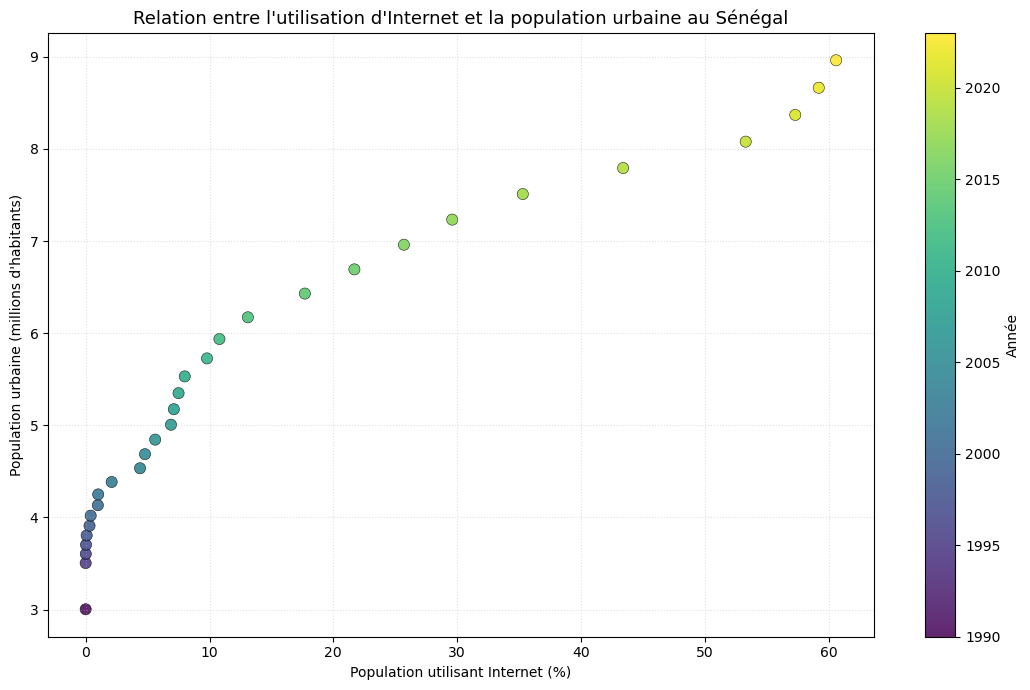

In [36]:
fig, ax = plt.subplots(figsize=(11, 7))

# La couleur des points représente l'année d'observation.
nuage = ax.scatter(
    donnees_q13["InternetUsage"],
    donnees_q13["UrbanPop_millions"],
    c=donnees_q13["Year"],
    cmap="viridis",
    s=65,
    alpha=0.85,
    edgecolors="black",
    linewidths=0.4
)

# Ajouter une barre de couleurs pour identifier les années.
barre_couleurs = fig.colorbar(nuage, ax=ax)
barre_couleurs.set_label("Année")

ax.set_title(
    "Relation entre l'utilisation d'Internet et la population urbaine au Sénégal",
    fontsize=13
)
ax.set_xlabel("Population utilisant Internet (%)")
ax.set_ylabel("Population urbaine (millions d'habitants)")

ax.grid(
    axis="both",
    linestyle=":",
    alpha=0.4
)

fig.tight_layout()
plt.show()

**Après l'observation graphique, nous calculons le coefficient de corrélation de Pearson entre le taux d'utilisation d'Internet et la population urbaine.**

Ce coefficient permet de mesurer le sens et l'intensité de leur relation linéaire. Il varie entre -1 et +1 :

- Une valeur proche de +1 indique une forte association linéaire positive.
- Une valeur proche de -1 indique une forte association linéaire négative.
- Une valeur proche de 0 indique une faible association linéaire.

Le calcul porte uniquement sur les 30 années pour lesquelles les deux indicateurs sont disponibles.

In [37]:
# Calculer la corrélation de Pearson entre les deux variables.
correlation_q13 = donnees_q13[
    ["InternetUsage", "UrbanPop"]
].corr(method="pearson")

correlation_q13

,InternetUsage,UrbanPop
InternetUsage,1.000000,0.948764
UrbanPop,0.948764,1.000000


### Le nuage de points met en évidence une relation positive entre le taux d'utilisation d'Internet et la population urbaine au Sénégal. Cette observation est confirmée par le coefficient de corrélation de Pearson, qui s'élève à 0,9488 sur les 30 observations disponibles.

### Ce résultat indique une très forte association linéaire positive entre les deux variables. Autrement dit, les années caractérisées par une population urbaine plus importante présentent généralement un taux d'utilisation d'Internet plus élevé.

### Toutefois, les deux indicateurs évoluent également au fil du temps. Cette progression commune peut contribuer à expliquer la forte corrélation observée. Le résultat ne permet donc pas d'établir une relation de causalité entre urbanisation et utilisation d'Internet.

## Conclusion générale

Cette analyse a permis d'explorer plusieurs dimensions de l'évolution du Sénégal entre 1975 et 2023 à partir des indicateurs disponibles dans la base.

Les résultats mettent notamment en évidence :

- une hausse du PIB moyen par habitant sur la période 2000–2020, avec une moyenne annuelle de **1 165,79 USD** ;
- une progression de l'espérance de vie moyenne, de **44,37 ans** pour les observations disponibles des années 1970 à **67,71 ans** pour celles des années 2020 ;
- un taux de chômage maximal observé de **6,757 % en 2015** parmi les données disponibles (la série ne commence qu'en 1991) ;
- une croissance démographique de **117,46 %** entre 1990 et 2020 ;
- une progression des taux bruts de scolarisation primaire et secondaire, ainsi qu'une forte association positive entre leurs valeurs annuelles appariées (**r = 0,8408**) ;
- un écart moyen de **5,27 points de pourcentage** entre les taux bruts de scolarisation primaire des garçons et des filles (garçons moins filles), avec des périodes où les taux féminins dépassent les taux masculins ;
- un écart absolu maximal de **318 045 personnes** entre les populations masculine et féminine en 2023 ;
- une forte association positive entre l'utilisation d'Internet et la population urbaine (**r = 0,9488**) sur les 30 observations disponibles.

Ces résultats doivent être interprétés en tenant compte des limites du jeu de données : certaines années sont absentes, plusieurs indicateurs comportent des valeurs manquantes et les périodes de disponibilité diffèrent selon les variables. Les corrélations décrivent des associations statistiques et ne démontrent pas de relations de causalité.

Ce travail illustre ainsi l'importance de vérifier la qualité et la couverture des données avant de calculer des indicateurs, de choisir des visualisations adaptées et de formuler des conclusions proportionnées aux informations réellement disponibles.


Nous fermons la connexion à la base SQLite, car les opérations d'exploration et de chargement sont terminées.

In [38]:
connexion.close()